# Task 01

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import LabelEncoder, OneHotEncoder
from sklearn.preprocessing import MinMaxScaler, StandardScaler

%matplotlib inline

print("all libraries are loaded!")

# loading the csv file
file_path = "titanic.csv"
df = pd.read_csv(file_path)

# displaying first 10 rows
df.head(10)

all libraries are loaded!


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S
5,6,0,3,"Moran, Mr. James",male,NaN,0,0,330877,8.4583,NaN,Q
6,7,0,1,"McCarthy, Mr. Timothy J",male,54.0,0,0,17463,51.8625,E46,S
7,8,0,3,"Palsson, Master. Gosta Leonard",male,2.0,3,1,349909,21.0750,NaN,S
8,9,1,3,"Johnson, Mrs. Oscar W (Elisabeth Vilhelmina Berg)",female,27.0,0,2,347742,11.1333,NaN,S
9,10,1,2,"Nasser, Mrs. Nicholas (Adele Achem)",female,14.0,1,0,237736,30.0708,NaN,C


In [ ]:
# shape display
print(f"Shape: {df.shape}")

# column names and data type display
print(df.columns.tolist())

df.dtypes

Shape: (891, 12)
['PassengerId', 'Survived', 'Pclass', 'Name', 'Sex', 'Age', 'SibSp', 'Parch', 'Ticket', 'Fare', 'Cabin', 'Embarked']


,0
PassengerId,int64
Survived,int64
Pclass,int64
Name,object
Sex,object
Age,float64
SibSp,int64
Parch,int64
Ticket,object
Fare,float64


In [ ]:
# passengers in each embarkation port
df['Embarked'].value_counts()

,count
Embarked,
S,644
C,168
Q,77


In [ ]:
# percentage of missing values for every column
round((df.isnull().mean() * 100), 2)

,0
PassengerId,0.00
Survived,0.00
Pclass,0.00
Name,0.00
Sex,0.00
Age,19.87
SibSp,0.00
Parch,0.00
Ticket,0.00
Fare,0.00


# Task 02

In [ ]:
# Drop the Cabin column.
df = df.drop(columns=['Cabin'])
df.shape[1]

11

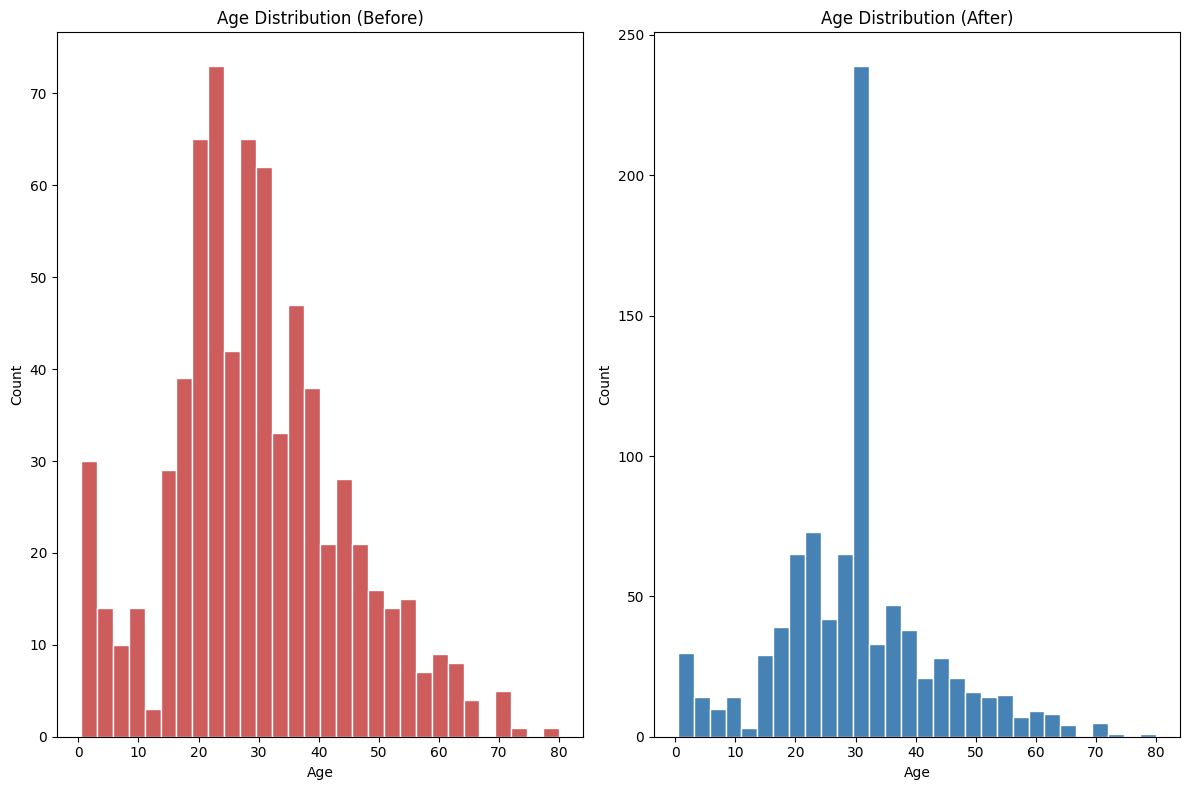

In [ ]:
# histogram comparison (before)
fig, axes = plt.subplots(1, 2, figsize=(12, 8))

axes[0].hist(df['Age'].dropna(), bins=30, color='indianred', edgecolor='white')
axes[0].set_title("Age Distribution (Before)")
axes[0].set_xlabel("Age")
axes[0].set_ylabel("Count")

# filling missing Age values with the mean
mean_age = df['Age'].mean()
df['Age'] = df['Age'].fillna(mean_age)

# histogram comparison (after)
axes[1].hist(df['Age'].dropna(), bins=30, color='steelblue', edgecolor='white')
axes[1].set_title("Age Distribution (After)")
axes[1].set_xlabel("Age")
axes[1].set_ylabel("Count")

plt.tight_layout()
plt.show()


In [ ]:
# filling missing Embarked values with the mode
embarked_mode = df['Embarked'].mode()[0]
df['Embarked'] = df['Embarked'].fillna(embarked_mode)

In [ ]:
print(f"Embarked Missing Count: {df['Embarked'].isnull().sum()}")
print(f"Age Missing Count: {df['Age'].isnull().sum()}")

Embarked Missing Count: 0
Age Missing Count: 0


# Task 03

In [ ]:
# label Encoding to the Sex column
le = LabelEncoder()
df['Sex_Encoded'] = le.fit_transform(df['Sex'])

print("Classes: ", le.classes_)
print(df[['Sex', 'Sex_Encoded']].head())

Classes:  ['female' 'male']
      Sex  Sex_Encoded
0    male            1
1  female            0
2  female            0
3  female            0
4    male            1


In [ ]:
# One-Hot Encoding to the Embarked column with drop first=True

embarked_dummies = pd.get_dummies(df['Embarked'], prefix='Embarked', drop_first=True)
print(embarked_dummies.head())

   Embarked_Q  Embarked_S
0       False        True
1       False       False
2       False        True
3       False        True
4       False        True


In [ ]:
# Min-Max Scaling to both Age and Fare Applied
minmax = MinMaxScaler()

df[['Age_minmax', 'Fare_minmax']] = minmax.fit_transform(df[['Age', 'Fare']])
print(df[['Age', 'Age_minmax', 'Fare', 'Fare_minmax']].head())

    Age  Age_minmax     Fare  Fare_minmax
0  22.0    0.271174   7.2500     0.014151
1  38.0    0.472229  71.2833     0.139136
2  26.0    0.321438   7.9250     0.015469
3  35.0    0.434531  53.1000     0.103644
4  35.0    0.434531   8.0500     0.015713


# Task 04

#### Task 04 - (a)

Text(0, 0.5, 'Count')

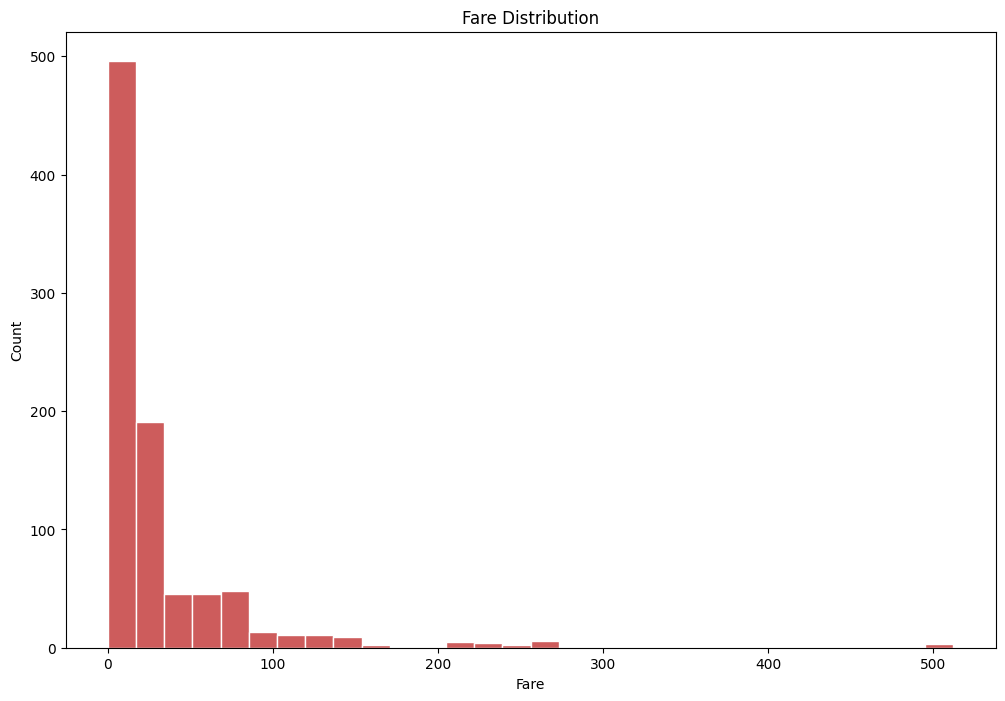

In [ ]:
# histogram distribution of fare
fig, axes = plt.subplots(1, 1, figsize=(12, 8))

axes.hist(df['Fare'], bins=30, color='indianred', edgecolor='white')
axes.set_title("Fare Distribution")
axes.set_xlabel("Fare")
axes.set_ylabel("Count")

Task 04 - (b)

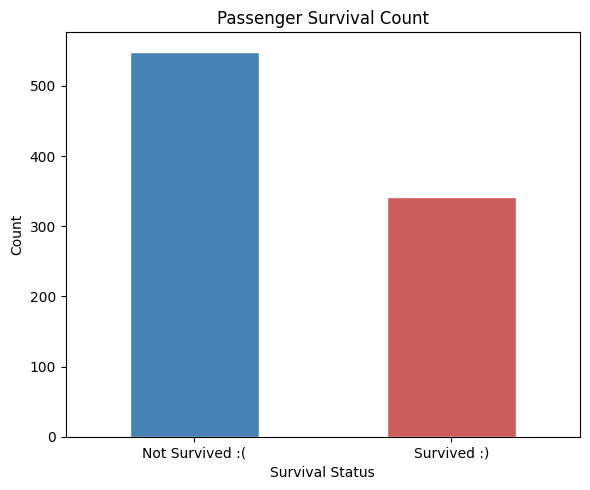

In [ ]:
# bar chart for survived vs not survived
fig, ax = plt.subplots(figsize=(6, 5))

# count values
counts = df['Survived'].value_counts().sort_index()

# plot
counts.plot(kind='bar', ax=ax, color=['steelblue', 'indianred'], edgecolor='white')

# labels
ax.set_title('Passenger Survival Count')
ax.set_xlabel('Survival Status')
ax.set_ylabel('Count')
ax.set_xticks([0, 1])
ax.set_xticklabels(['Not Survived :(', 'Survived :)'], rotation=0)

plt.tight_layout()
plt.show()

Task 04 - (c)

/tmp/ipykernel_2090/1771625349.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='Pclass', y='Fare', palette={'1': 'steelblue', '2': 'lightgreen', '3': 'indianred'}, ax=ax)


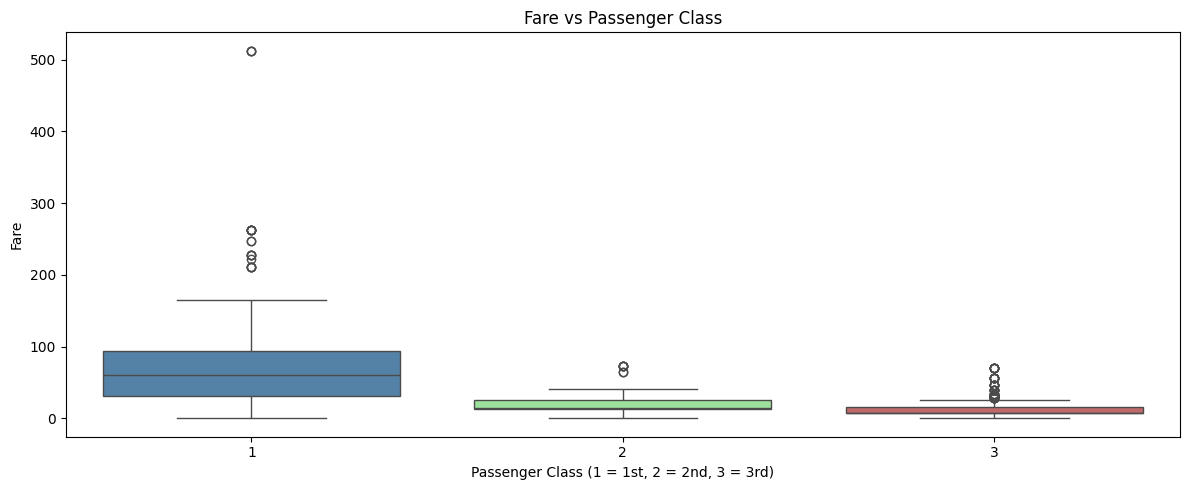

In [ ]:
# box-plots of fare
fig, ax = plt.subplots(figsize=(12, 5))

sns.boxplot(data=df, x='Pclass', y='Fare', palette={'1': 'steelblue', '2': 'lightgreen', '3': 'indianred'}, ax=ax)

ax.set_title("Fare vs Passenger Class")
ax.set_xlabel("Passenger Class (1 = 1st, 2 = 2nd, 3 = 3rd)")
ax.set_ylabel("Fare")

plt.tight_layout()
plt.show()

In [ ]:
# most outliers
for pclass in df['Pclass'].unique():

    class_data = df[df['Pclass'] == pclass]['Fare']

    Q1 = class_data.quantile(0.25)
    Q3 = class_data.quantile(0.75)
    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outliers = class_data[(class_data < lower_bound) | (class_data > upper_bound)]

    print(f"\nClass {pclass}")
    print(f"Q1 = {Q1:.2f}, Q3 = {Q3:.2f}, IQR = {IQR:.2f}")
    print(f"Lower bound: {lower_bound:.2f}, Upper bound: {upper_bound:.2f}")
    print(f"Number of outliers in Fare: {len(outliers)}")


Class 3
Q1 = 7.75, Q3 = 15.50, IQR = 7.75
Lower bound: -3.88, Upper bound: 27.12
Number of outliers in Fare: 52

Class 1
Q1 = 30.92, Q3 = 93.50, IQR = 62.58
Lower bound: -62.94, Upper bound: 187.36
Number of outliers in Fare: 20

Class 2
Q1 = 13.00, Q3 = 26.00, IQR = 13.00
Lower bound: -6.50, Upper bound: 45.50
Number of outliers in Fare: 7


In [ ]:
# class with the highest median fare
median_fares = df.groupby('Pclass')['Fare'].median()

highest_class = median_fares.idxmax()

print(f"\nClass with highest median fare: {highest_class}")


Class with highest median fare: 1


Task 04 - (d)

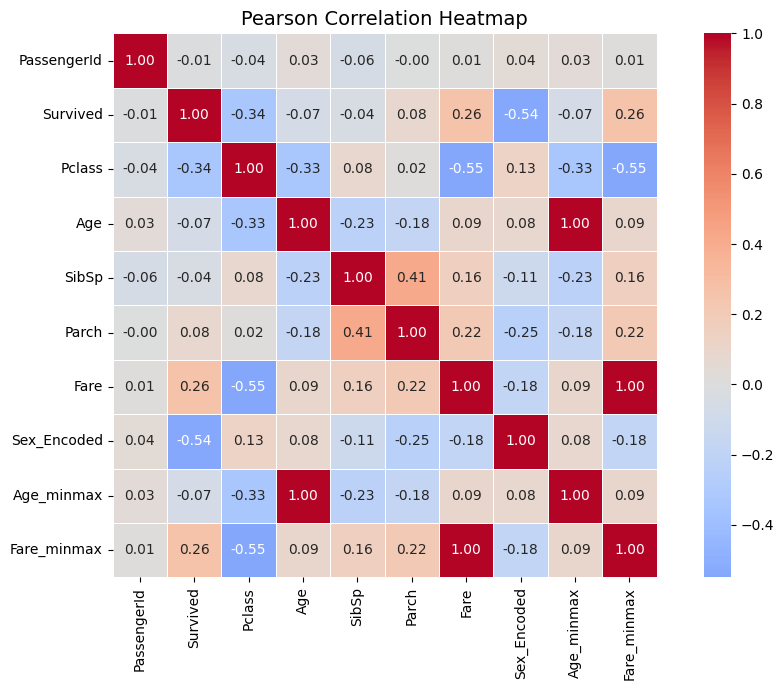

In [ ]:
# correlation matrix
numeric_df = df.select_dtypes(include=[np.number])

corr_matrix = numeric_df.corr()

plt.figure(figsize=(10, 7))
sns.heatmap(
    corr_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    linewidths=0.5,
    square=True
)

plt.title("Pearson Correlation Heatmap", fontsize=14)
plt.tight_layout()
plt.show()

In [ ]:
# top 3 features most correlated with Survived

# Correlation with Survived column
corr_survived = corr_matrix['Survived'].drop('Survived')

# Take absolute values and sort
top_3 = corr_survived.abs().sort_values(ascending=False).head(3)

print("Top 3 features most correlated with Survived:")
print(top_3)

Top 3 features most correlated with Survived:
Sex_Encoded    0.543351
Pclass         0.338481
Fare           0.257307
Name: Survived, dtype: float64


Task 04 - (e)

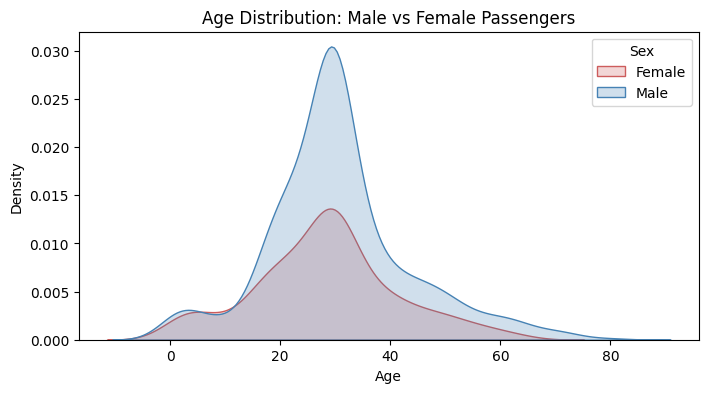

In [ ]:
# age distribution: male vs female
plt.figure(figsize=(8, 4))

sns.kdeplot(
    data=df,
    x='Age',
    hue='Sex',
    fill=True,
    palette={'male': 'steelblue', 'female': 'indianred'}
)

plt.title("Age Distribution: Male vs Female Passengers")
plt.xlabel("Age")
plt.ylabel("Density")

plt.legend(title="Sex", labels=["Female", "Male"])

plt.show()

# Task 05

/tmp/ipykernel_2090/3720858848.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


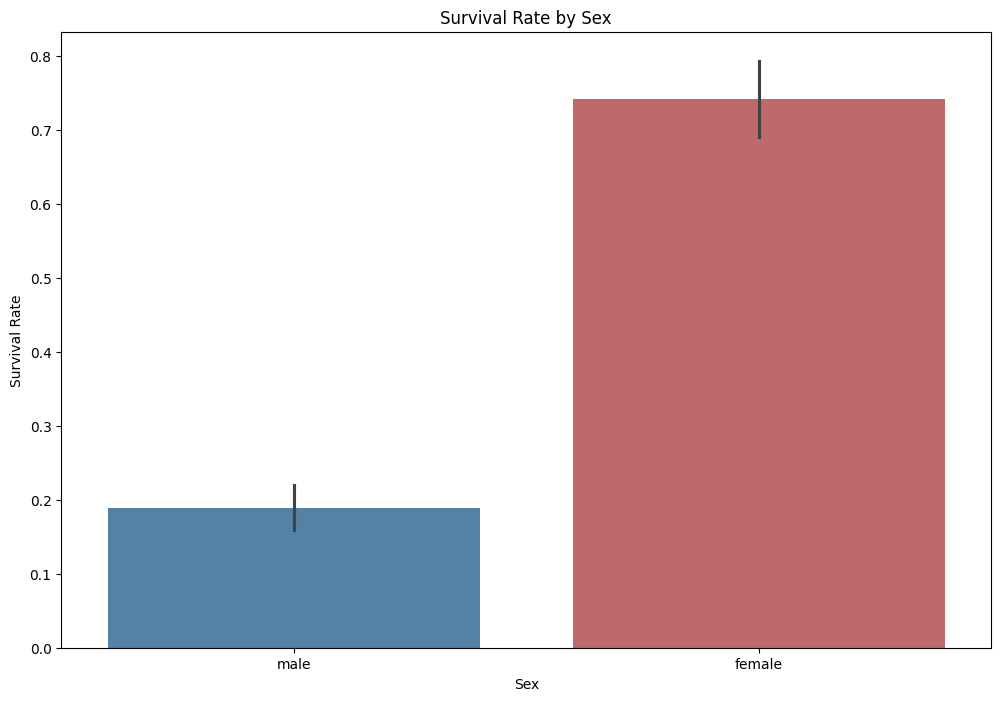

In [ ]:
# survival rate by sex
plt.figure(figsize=(12,8))

sns.barplot(
    data=df,
    x='Sex',
    y='Survived',
    palette={'male': 'steelblue', 'female': 'indianred'}
)

plt.title("Survival Rate by Sex")
plt.xlabel("Sex")
plt.ylabel("Survival Rate")

plt.show()

/tmp/ipykernel_2090/325834660.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


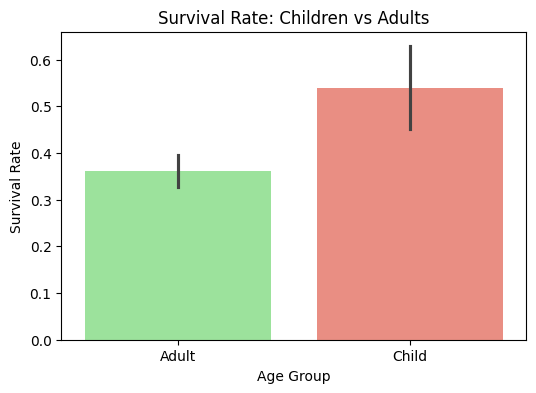

In [ ]:
# survival rate: children vs adults
df['AgeGroup'] = df['Age'].apply(lambda x: 'Child' if x < 18 else 'Adult')

plt.figure(figsize=(6,4))

sns.barplot(
    data=df,
    x='AgeGroup',
    y='Survived',
    palette={'Child': 'salmon', 'Adult': 'lightgreen'}
)

plt.title("Survival Rate: Children vs Adults")
plt.xlabel("Age Group")
plt.ylabel("Survival Rate")

plt.show()

In [ ]:
df['AgeGroup'] = df['Age'].apply(lambda x: 'Child' if x < 18 else 'Adult')
df['AgeGroup'].value_counts()

,count
AgeGroup,
Adult,778
Child,113


In [ ]:
df['Sex'].value_counts()

,count
Sex,
male,577
female,314
